Język: [English](examples.en.ipynb) | **Polski**

# Wykład 05. Generalizacja, overfitting i regularyzacja

Materiał uzupełnia [`lecture.md`](lecture.md). Pierwsza część sprawdza wzory
L2 i weight decay dla SGD, Adama i AdamW oraz działanie inverted dropout.
Następnie porównywane są trzy pojemności modelu i metody regularyzacji dla
architektury podatnej na przeuczenie.


In [1]:
import copy

import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Używane urządzenie: {device}")

Używane urządzenie: cpu


## 1. Weryfikacja L2 i weight decay dla SGD, Adama i AdamW

Obliczenia korzystają z $\theta_0=2$, $\eta=0{,}1$, $\lambda=0{,}5$ oraz
$\ell(\theta)=\tfrac12\theta^2$, czyli wartości z przykładu rozwiązanego
na wykładzie.


In [2]:
def one_step(opt_cls, lr, weight_decay, **kwargs):
    theta = torch.tensor([2.0], requires_grad=True)
    opt = opt_cls([theta], lr=lr, weight_decay=weight_decay, **kwargs)
    opt.zero_grad()
    loss = 0.5 * theta[0] ** 2
    loss.backward()
    opt.step()
    return theta.item()


sgd_no_reg = one_step(torch.optim.SGD, lr=0.1, weight_decay=0.0)
sgd_l2 = one_step(torch.optim.SGD, lr=0.1, weight_decay=0.5)
adam_no_reg = one_step(torch.optim.Adam, lr=0.1, weight_decay=0.0)
adam_wd = one_step(torch.optim.Adam, lr=0.1, weight_decay=0.5)
adamw_wd = one_step(torch.optim.AdamW, lr=0.1, weight_decay=0.5)

print(f"SGD bez regularyzacji:       theta_1 = {sgd_no_reg:.4f}  (oczekiwane 1.8000)")
print(f"SGD z L2/weight_decay=0.5:   theta_1 = {sgd_l2:.4f}  (oczekiwane 1.7000)")
print(f"Adam bez regularyzacji:      theta_1 = {adam_no_reg:.4f}  (oczekiwane 1.9000)")
print(f"Adam z weight_decay=0.5:     theta_1 = {adam_wd:.4f}  (oczekiwane 1.9000 - BEZ ZMIAN!)")
print(f"AdamW z weight_decay=0.5:    theta_1 = {adamw_wd:.4f}  (oczekiwane 1.8000)")

assert abs(sgd_no_reg - 1.8) < 1e-3
assert abs(sgd_l2 - 1.7) < 1e-3
assert abs(adam_wd - adam_no_reg) < 1e-6, (
    "Adam z weight_decay powinien tu dac taki sam wynik co bez"
)
assert abs(adamw_wd - 1.8) < 1e-3
assert abs(adamw_wd - adam_wd) > 1e-3, "AdamW i Adam(weight_decay) powinny sie tu roznic"
print("\nOK: wszystkie cztery wartosci zgadzaja sie z wyprowadzeniem na wykladzie.")

SGD bez regularyzacji:       theta_1 = 1.8000  (oczekiwane 1.8000)
SGD z L2/weight_decay=0.5:   theta_1 = 1.7000  (oczekiwane 1.7000)
Adam bez regularyzacji:      theta_1 = 1.9000  (oczekiwane 1.9000)
Adam z weight_decay=0.5:     theta_1 = 1.9000  (oczekiwane 1.9000 - BEZ ZMIAN!)
AdamW z weight_decay=0.5:    theta_1 = 1.8000  (oczekiwane 1.8000)

OK: wszystkie cztery wartosci zgadzaja sie z wyprowadzeniem na wykladzie.


## 2. Weryfikacja inverted dropout i trybu `eval()`


In [3]:
torch.manual_seed(0)
x_ones = torch.ones(10_000)
dropout = nn.Dropout(p=0.3)

dropout.train()
y_train_mode = dropout(x_ones)
frac_zero = (y_train_mode == 0).float().mean().item()
nonzero_value = y_train_mode[y_train_mode != 0][0].item()

print(f"tryb train(): srednia wyjscia = {y_train_mode.mean().item():.4f}  (oczekiwane ~1.0)")
print(f"tryb train(): odsetek zer = {frac_zero:.4f}  (oczekiwane ~0.3)")
print(
    f"tryb train(): wartosc niezerowa = {nonzero_value:.4f}  (oczekiwane 1/(1-0.3)={1 / 0.7:.4f})"
)

dropout.eval()
y_eval_mode = dropout(x_ones)
print(f"tryb eval(): wyjscie == wejscie dokladnie? {torch.equal(y_eval_mode, x_ones)}")

# eval() a liczenie gradientow - to NIEZALEZNE mechanizmy
x_grad_check = torch.ones(5, requires_grad=True)
dropout.eval()
y_grad_check = dropout(x_grad_check)
y_grad_check.sum().backward()
print(f"tryb eval(): x.grad = {x_grad_check.grad.tolist()}  (gradient liczony normalnie)")
print(f"tryb eval(): y.requires_grad = {y_grad_check.requires_grad}")

tryb train(): srednia wyjscia = 0.9960  (oczekiwane ~1.0)
tryb train(): odsetek zer = 0.3028  (oczekiwane ~0.3)
tryb train(): wartosc niezerowa = 1.4286  (oczekiwane 1/(1-0.3)=1.4286)
tryb eval(): wyjscie == wejscie dokladnie? True
tryb eval(): x.grad = [1.0, 1.0, 1.0, 1.0, 1.0]  (gradient liczony normalnie)
tryb eval(): y.requires_grad = True


## 3. Trzy pojemności, ten sam problem

Problem ma postać $y = \sin(3x) + 0{,}3x + \varepsilon$. Zbiór zawiera
$N=30$ zaszumionych punktów treningowych oraz $N=200$ punktów
walidacyjnych z tego samego rozkładu.


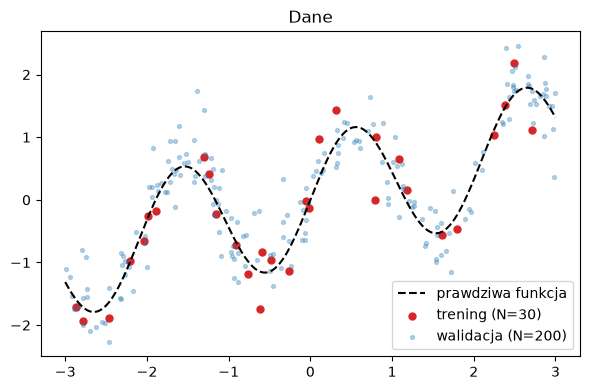

In [4]:
def true_fn(x):
    return torch.sin(3 * x) + 0.3 * x


def make_data(n, noise_std, seed):
    g = torch.Generator().manual_seed(seed)
    x = torch.empty(n).uniform_(-3, 3, generator=g)
    y = true_fn(x) + torch.randn(n, generator=g) * noise_std
    return x.unsqueeze(-1), y.unsqueeze(-1)


N_TRAIN = 30
NOISE_STD = 0.4
X_train, y_train = make_data(N_TRAIN, NOISE_STD, seed=0)
X_val, y_val = make_data(200, NOISE_STD, seed=100)

x_line = torch.linspace(-3, 3, 200).unsqueeze(-1)

plt.figure(figsize=(6, 4))
plt.plot(x_line, true_fn(x_line), color="black", linestyle="--", label="prawdziwa funkcja")
plt.scatter(X_train, y_train, s=25, color="tab:red", label="trening (N=30)")
plt.scatter(X_val, y_val, s=8, alpha=0.3, color="tab:blue", label="walidacja (N=200)")
plt.legend()
plt.title("Dane")
plt.tight_layout()
plt.show()

In [5]:
def make_model(hidden_sizes, seed, dropout_p=0.0):
    torch.manual_seed(seed)
    layers = []
    in_dim = 1
    for h in hidden_sizes:
        layers.append(nn.Linear(in_dim, h))
        layers.append(nn.ReLU())
        if dropout_p > 0:
            layers.append(nn.Dropout(dropout_p))
        in_dim = h
    layers.append(nn.Linear(in_dim, 1))
    return nn.Sequential(*layers)


def train_model(model, epochs, lr=0.005, weight_decay=0.0, use_adamw=False):
    OptCls = torch.optim.AdamW if use_adamw else torch.optim.Adam
    opt = OptCls(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.MSELoss()
    train_losses, val_losses = [], []
    for _ in range(epochs):
        model.train()
        opt.zero_grad()
        pred = model(X_train)
        loss = loss_fn(pred, y_train)
        loss.backward()
        opt.step()
        train_losses.append(loss.item())
        model.eval()
        with torch.no_grad():
            val_losses.append(loss_fn(model(X_val), y_val).item())
    return train_losses, val_losses


EPOCHS = 2000
MODEL_SEED = 1

capacities = {
    "mala (1x4)": [4],
    "srednia (2x16)": [16, 16],
    "duza (3x128)": [128, 128, 128],
}

capacity_results = {}
for name, hidden in capacities.items():
    model = make_model(hidden, MODEL_SEED)
    tl, vl = train_model(model, EPOCHS)
    capacity_results[name] = (model, tl, vl, sum(p.numel() for p in model.parameters()))

print(
    f"{'model':18s}{'parametry':>10s}{'train_final':>14s}{'val_min':>12s}{'@epoka':>8s}{'val_final':>12s}"
)
for name, (model, tl, vl, n_params) in capacity_results.items():
    val_min = min(vl)
    val_min_epoch = vl.index(val_min)
    print(
        f"{name:18s}{n_params:>10d}{tl[-1]:>14.4f}{val_min:>12.4f}{val_min_epoch:>8d}{vl[-1]:>12.4f}"
    )

model              parametry   train_final     val_min  @epoka   val_final
mala (1x4)                13        0.5055      0.6210    1765      0.6219
srednia (2x16)           321        0.0907      0.2256    1906      0.2440
duza (3x128)           33409        0.0452      0.2091     378      0.4622


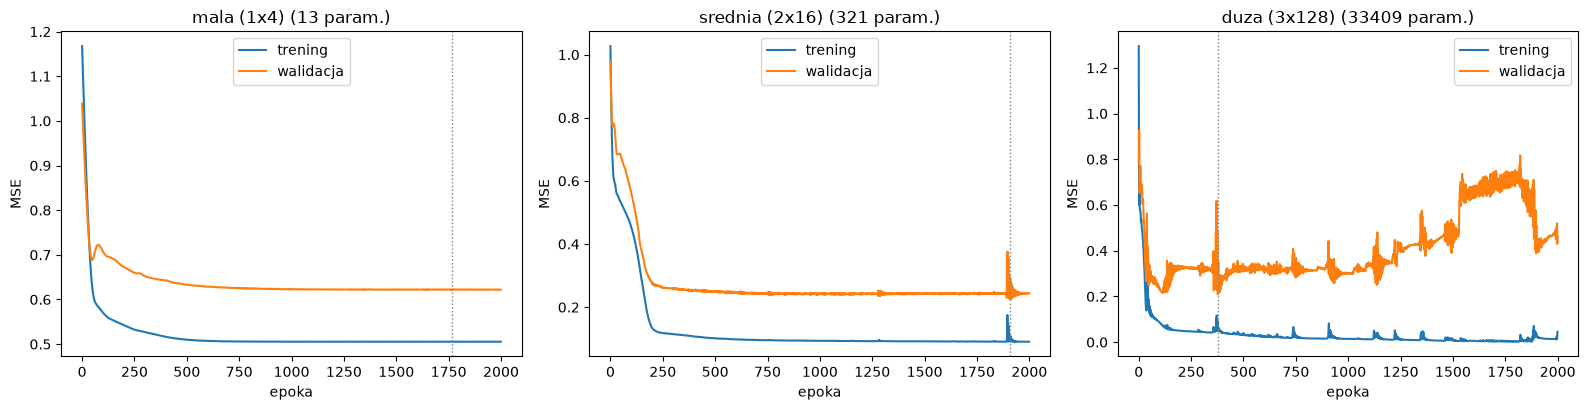

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (name, (model, tl, vl, n_params)) in zip(axes, capacity_results.items()):
    ax.plot(tl, label="trening")
    ax.plot(vl, label="walidacja")
    val_min_epoch = vl.index(min(vl))
    ax.axvline(val_min_epoch, color="gray", linestyle=":", linewidth=1)
    ax.set_title(f"{name} ({n_params} param.)")
    ax.set_xlabel("epoka")
    ax.set_ylabel("MSE")
    ax.legend()
plt.tight_layout()
plt.show()

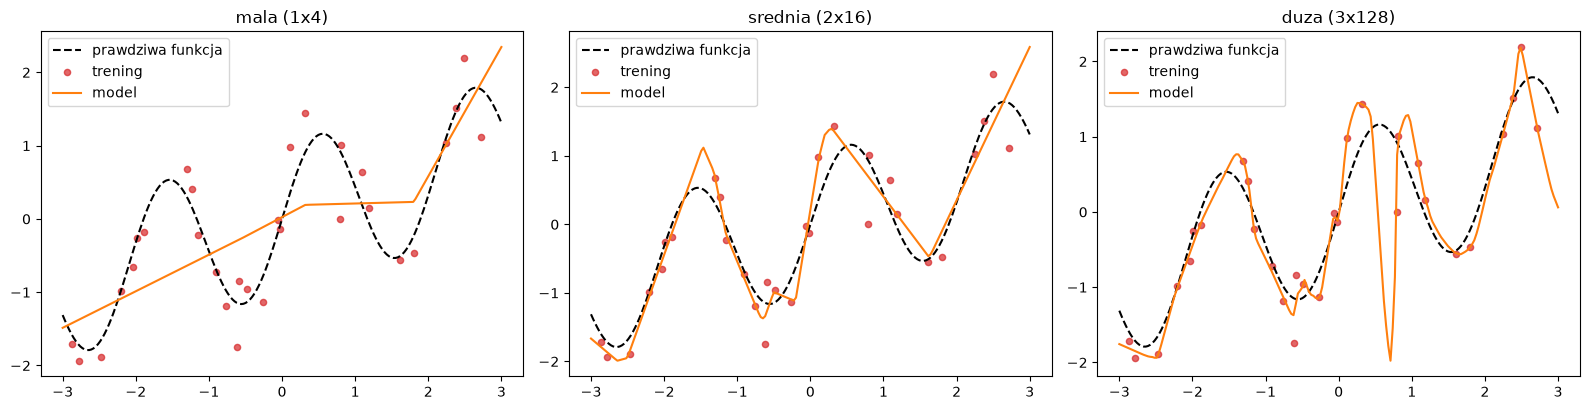

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (name, (model, tl, vl, n_params)) in zip(axes, capacity_results.items()):
    model.eval()
    with torch.no_grad():
        y_line = model(x_line)
    ax.plot(x_line, true_fn(x_line), color="black", linestyle="--", label="prawdziwa funkcja")
    ax.scatter(X_train, y_train, s=20, color="tab:red", alpha=0.7, label="trening")
    ax.plot(x_line, y_line, color="tab:orange", label="model")
    ax.set_title(name)
    ax.legend()
plt.tight_layout()
plt.show()

## 4. Regularyzacja na modelu, który się przeuczał

Dalsze eksperymenty korzystają z architektury `[128,128,128]` z sekcji 3.


In [8]:
def summarize(name, tl, vl):
    val_min = min(vl)
    val_min_epoch = vl.index(val_min)
    print(
        f"{name:28s} train_final={tl[-1]:.4f}  val_min={val_min:.4f}@{val_min_epoch}  "
        f"val_final={vl[-1]:.4f}"
    )


baseline_model, baseline_tl, baseline_vl, _ = capacity_results["duza (3x128)"]
summarize("baseline (bez regularyzacji)", baseline_tl, baseline_vl)

baseline (bez regularyzacji) train_final=0.0452  val_min=0.2091@378  val_final=0.4622


### Weight decay (AdamW)

In [9]:
wd_results = {}
for wd in [1e-4, 1e-3, 1e-2, 1e-1]:
    model = make_model([128, 128, 128], MODEL_SEED)
    tl, vl = train_model(model, EPOCHS, weight_decay=wd, use_adamw=True)
    wd_results[wd] = (tl, vl)
    summarize(f"AdamW weight_decay={wd}", tl, vl)

AdamW weight_decay=0.0001    train_final=0.0194  val_min=0.2004@643  val_final=0.3175


AdamW weight_decay=0.001     train_final=0.0135  val_min=0.1963@408  val_final=0.2941


AdamW weight_decay=0.01      train_final=0.0216  val_min=0.2080@189  val_final=0.2671


AdamW weight_decay=0.1       train_final=0.0191  val_min=0.2079@146  val_final=0.2824


### Dropout, w tym zbyt silny wariant z p=0,5

In [10]:
dropout_results = {}
for p in [0.1, 0.2, 0.3, 0.5]:
    model = make_model([128, 128, 128], MODEL_SEED, dropout_p=p)
    tl, vl = train_model(model, EPOCHS)
    dropout_results[p] = (tl, vl)
    summarize(f"dropout p={p}", tl, vl)

dropout p=0.1                train_final=0.0539  val_min=0.1681@1258  val_final=0.2129


dropout p=0.2                train_final=0.0897  val_min=0.1816@1844  val_final=0.2182


dropout p=0.3                train_final=0.1128  val_min=0.1964@1946  val_final=0.2228


dropout p=0.5                train_final=0.1671  val_min=0.2476@1786  val_final=0.3085


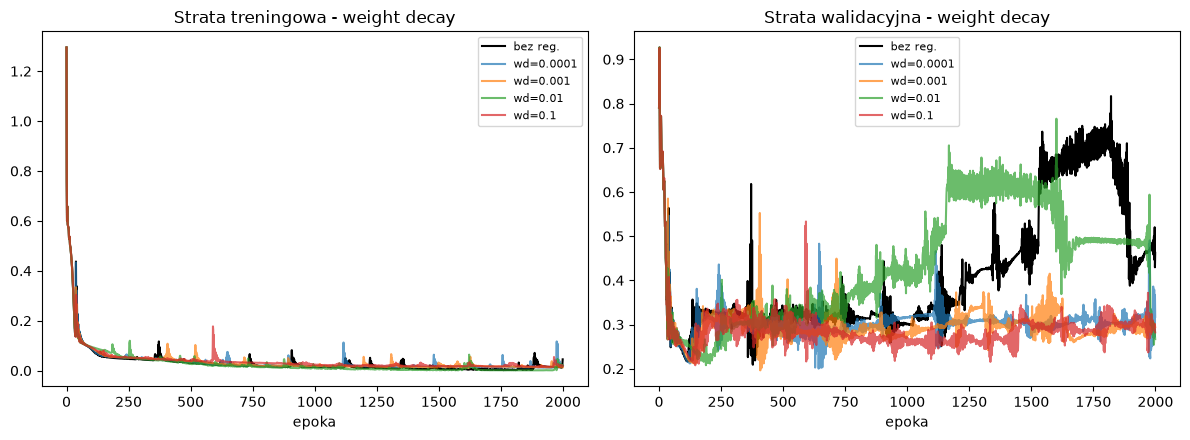

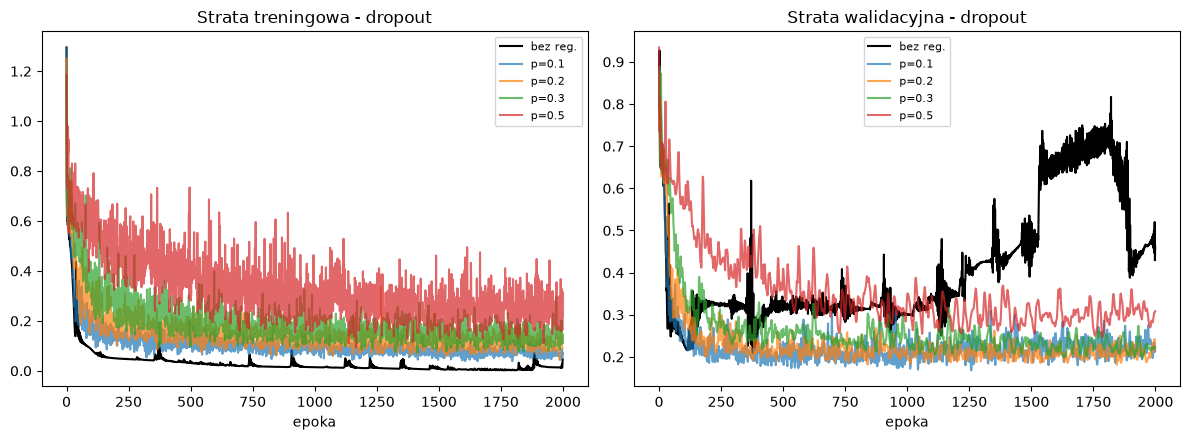

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(baseline_tl, label="bez reg.", color="black")
for wd, (tl, vl) in wd_results.items():
    axes[0].plot(tl, label=f"wd={wd}", alpha=0.7)
axes[0].set_title("Strata treningowa - weight decay")
axes[0].set_xlabel("epoka")
axes[0].legend(fontsize=8)

axes[1].plot(baseline_vl, label="bez reg.", color="black")
for wd, (tl, vl) in wd_results.items():
    axes[1].plot(vl, label=f"wd={wd}", alpha=0.7)
axes[1].set_title("Strata walidacyjna - weight decay")
axes[1].set_xlabel("epoka")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(baseline_tl, label="bez reg.", color="black")
for p, (tl, vl) in dropout_results.items():
    axes[0].plot(tl, label=f"p={p}", alpha=0.7)
axes[0].set_title("Strata treningowa - dropout")
axes[0].set_xlabel("epoka")
axes[0].legend(fontsize=8)

axes[1].plot(baseline_vl, label="bez reg.", color="black")
for p, (tl, vl) in dropout_results.items():
    axes[1].plot(vl, label=f"p={p}", alpha=0.7)
axes[1].set_title("Strata walidacyjna - dropout")
axes[1].set_xlabel("epoka")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Early stopping z przywróceniem najlepszego stanu

In [12]:
def train_with_early_stopping(model, epochs, lr=0.005, patience=50, min_delta=1e-4):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    best_val = float("inf")
    best_state = None
    best_epoch = -1
    epochs_since_improvement = 0
    train_losses, val_losses = [], []
    stopped_epoch = epochs

    for epoch in range(epochs):
        model.train()
        opt.zero_grad()
        pred = model(X_train)
        loss = loss_fn(pred, y_train)
        loss.backward()
        opt.step()
        train_losses.append(loss.item())

        model.eval()
        with torch.no_grad():
            v = loss_fn(model(X_val), y_val).item()
        val_losses.append(v)

        if v < best_val - min_delta:
            best_val = v
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            epochs_since_improvement = 0
        else:
            epochs_since_improvement += 1
            if epochs_since_improvement >= patience:
                stopped_epoch = epoch
                break

    model.load_state_dict(best_state)
    return model, train_losses, val_losses, best_epoch, stopped_epoch


es_model = make_model([128, 128, 128], MODEL_SEED)
es_model, es_tl, es_vl, es_best_epoch, es_stopped_epoch = train_with_early_stopping(
    es_model, epochs=EPOCHS, patience=50
)

print(
    f"Zatrzymano na epoce {es_stopped_epoch}; najlepsza epoka = {es_best_epoch}, "
    f"strata walidacyjna tam = {es_vl[es_best_epoch]:.4f}"
)
print(
    f"Strata walidacyjna w momencie zatrzymania (ostatnia epoka) = {es_vl[-1]:.4f}  "
    f"<- GORSZA niz najlepsza, to normalne"
)

# zweryfikuj, ze przywrocenie faktycznie zadzialalo
with torch.no_grad():
    restored_val = nn.MSELoss()(es_model(X_val), y_val).item()
print(
    f"Strata walidacyjna PO przywroceniu najlepszego stanu = {restored_val:.4f}  "
    f"(musi sie zgadzac z najlepsza powyzej)"
)
assert abs(restored_val - es_vl[es_best_epoch]) < 1e-6, (
    "przywrocenie stanu nie zadzialalo poprawnie!"
)
print("OK: przywrocenie najlepszego stanu dziala poprawnie.")

Zatrzymano na epoce 166; najlepsza epoka = 116, strata walidacyjna tam = 0.2164
Strata walidacyjna w momencie zatrzymania (ostatnia epoka) = 0.3343  <- GORSZA niz najlepsza, to normalne
Strata walidacyjna PO przywroceniu najlepszego stanu = 0.2164  (musi sie zgadzac z najlepsza powyzej)
OK: przywrocenie najlepszego stanu dziala poprawnie.


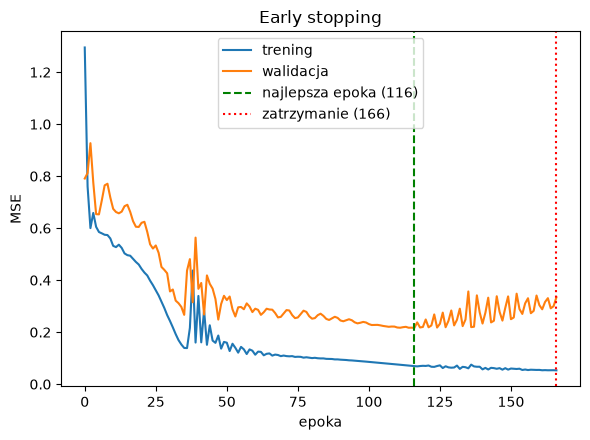

In [13]:
plt.figure(figsize=(6, 4.5))
plt.plot(es_tl, label="trening")
plt.plot(es_vl, label="walidacja")
best_label = f"najlepsza epoka ({es_best_epoch})"
plt.axvline(es_best_epoch, color="green", linestyle="--", label=best_label)
stop_label = f"zatrzymanie ({es_stopped_epoch})"
plt.axvline(es_stopped_epoch, color="red", linestyle=":", label=stop_label)
plt.xlabel("epoka")
plt.ylabel("MSE")
plt.title("Early stopping")
plt.legend()
plt.tight_layout()
plt.show()

### Interakcja dropout i early stopping przy tym samym `patience`

In [14]:
es_dropout_model = make_model([128, 128, 128], MODEL_SEED, dropout_p=0.1)
_, _, es_dropout_vl, es_dropout_best_epoch, es_dropout_stopped_epoch = train_with_early_stopping(
    es_dropout_model, epochs=EPOCHS, patience=50
)

es_dropout_best_val = es_dropout_vl[es_dropout_best_epoch]
print(
    f"Dropout p=0.1 + early stopping (patience=50): "
    f"zatrzymano={es_dropout_stopped_epoch}, najlepsza epoka={es_dropout_best_epoch}, "
    f"najlepsza strata={es_dropout_best_val:.4f}"
)
dropout01_vl = dropout_results[0.1][1]
dropout01_val_min = min(dropout01_vl)
print(
    f"Dla porownania, dropout p=0.1 wytrenowany w pelni (sekcja wyzej): "
    f"val_min={dropout01_val_min:.4f}@{dropout01_vl.index(dropout01_val_min)}"
)
print(
    "Early stopping z tym samym patience zatrzymal sie PRZEDWCZESNIE - "
    "szum wprowadzany przez dropout z epoki na epoke sprawia, ze ten sam prog "
    "cierpliwosci bywa zbyt niski."
)

Dropout p=0.1 + early stopping (patience=50): zatrzymano=252, najlepsza epoka=202, najlepsza strata=0.1856
Dla porownania, dropout p=0.1 wytrenowany w pelni (sekcja wyzej): val_min=0.1681@1258
Early stopping z tym samym patience zatrzymal sie PRZEDWCZESNIE - szum wprowadzany przez dropout z epoki na epoke sprawia, ze ten sam prog cierpliwosci bywa zbyt niski.


## 5. (Opcjonalnie) Wpływ liczby przykładów treningowych


N_train=  15: val_min=0.7387@18  val_final=1.2510  stosunek=1.69x


N_train=  30: val_min=0.2091@378  val_final=0.5202  stosunek=2.49x


N_train=  60: val_min=0.1936@237  val_final=0.2490  stosunek=1.29x


N_train= 120: val_min=0.1836@434  val_final=0.2107  stosunek=1.15x


N_train= 300: val_min=0.1568@477  val_final=0.1809  stosunek=1.15x


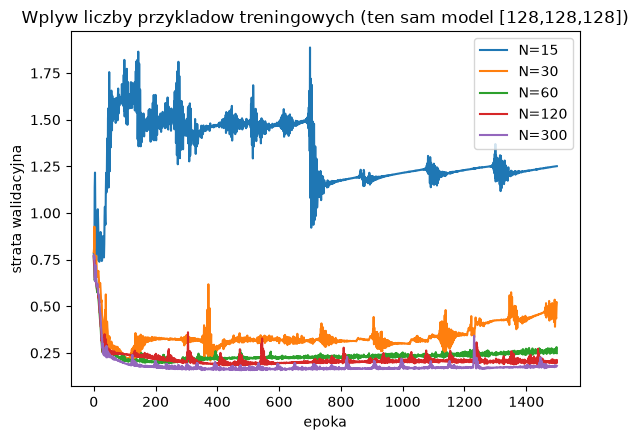

In [15]:
n_train_sweep = {}
for n in [15, 30, 60, 120, 300]:
    Xt, yt = make_data(n, NOISE_STD, seed=0)
    model = make_model([128, 128, 128], MODEL_SEED)
    opt = torch.optim.Adam(model.parameters(), lr=0.005)
    loss_fn = nn.MSELoss()
    tl, vl = [], []
    for _ in range(1500):
        model.train()
        opt.zero_grad()
        loss = loss_fn(model(Xt), yt)
        loss.backward()
        opt.step()
        tl.append(loss.item())
        model.eval()
        with torch.no_grad():
            vl.append(loss_fn(model(X_val), y_val).item())
    n_train_sweep[n] = (tl, vl)
    val_min = min(vl)
    print(
        f"N_train={n:4d}: val_min={val_min:.4f}@{vl.index(val_min)}  val_final={vl[-1]:.4f}  "
        f"stosunek={vl[-1] / val_min:.2f}x"
    )

plt.figure(figsize=(6, 4.5))
for n, (tl, vl) in n_train_sweep.items():
    plt.plot(vl, label=f"N={n}")
plt.xlabel("epoka")
plt.ylabel("strata walidacyjna")
plt.title("Wplyw liczby przykladow treningowych (ten sam model [128,128,128])")
plt.legend()
plt.tight_layout()
plt.show()

## Podsumowanie

- Overfitting został zmierzony liczbowo. Strata walidacyjna dużego modelu
  wcześnie osiąga minimum i rośnie, mimo dalszego spadku straty treningowej.
- Weight decay (AdamW) i dropout obie pomagają na tym problemie; dropout
  działał wyraźniej i bardziej konsekwentnie. Jest to obserwacja właściwa
  temu problemowi, a nie ogólne prawo.
- Zbyt silny dropout (p=0,5) zamienia overfitting w underfitting.
- Early stopping wymaga przywrócenia najlepszego stanu. Próg cierpliwości
  powinien uwzględniać poziom szumu metody, z którą jest łączony.

Pytania do dyskusji i bibliografia znajdują się w [`lecture.md`](lecture.md).
